# Übung 1 - Aufgabe 2 - Zeitpunkt der Kirschblüte

Der Start der Kirschblüte in der japanischen Stadt Kyoto wird seit Jahrhunderten nahezu Jahr für Jahr aufgezeichnet. Diese ist neben dem Wetter allgemein besonders von der durchschnittlichen Temperatur im März abhängig. Aufzeichnungen und Einschätzungen zum Wetter in diesem Zeitraum finden sich ebenfalls für Jahrhunderte. Entwickeln und trainieren Sie ein neuronales Netz, welches die durchschnittliche Märztemperatur und das Jahr aufnimmt, um eine Prognose für den Start der Kirschblüte zu geben. Diese Vorhersage soll als absoluter Jahrestag (99, 100, 101, usw.) geliefert werden. Ein Einbezug des Jahr soll hierbei vorgenommen werden, um mögliche Klimatrends zu berücksichtigen. Der Datensatz liegt als Semikolon-separiertes CSV-Dokument vor, welches die Spalten Jahr (AD), absoluter Jahrestag (Full-flowering date (DOY)) und durchschnittliche Märztemperatur (March-Mean-Temp) beinhaltet.

Diese Aufgabe hält sich sehr nah an das zweite Kapitel im Buch. Sie können es daher jederzeit als Referenz nutzen.

## 1. Nötige Imports vornehmen

Die benötigten Imports werden mit der folgenden Zelle vorgegeben. Der sklearn import ist optional für die Verwendung von Skalierern. 

In [52]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn import preprocessing
from pathlib import Path
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

## 2. Einlesen der Daten

Beginnen Sie mit dem Einlesen der Daten aus der Datei "FlowerAndTemp.CSV". Bedenken Sie, dass sie Datei Semikolons als Separator nutzt. Im Anschluss werden die Daten explizit in float32 umgewandelt.

In [53]:
path2file = Path('FlowerAndTemp.CSV')

if path2file.exists() is False:
    raise FileNotFoundError(path2file)

flower = np.loadtxt(path2file, delimiter=';', skiprows=1)
flower = flower.astype(np.float32)
flower[:10]

array([[853.  , 104.  ,   5.84],
       [864.  , 100.  ,   7.13],
       [866.  , 106.  ,   7.38],
       [891.  , 109.  ,   5.6 ],
       [892.  , 108.  ,   5.71],
       [894.  , 106.  ,   5.95],
       [895.  , 104.  ,   6.08],
       [896.  , 104.  ,   6.22],
       [902.  , 102.  ,   6.65],
       [908.  ,  98.  ,   6.93]], dtype=float32)

Der Datensatz besteht aus der Jahreszahl, dem Jahrestag und der Mean Temperatur im März. 
Als **Label** wird hierbei der Jahrestag verwendet, da dieser am Ende vorhergesagt werden soll. 
Als **Input** wird die Mean Temperatur im März verwendet, da diese Information nützlich ist. 
Die Jahreszahl wird verworfen, da keinerlei Information enthalten ist. 

In [54]:
y = flower[:,1]
print(y[:10])
X = flower[:,[0,2]]
print(X[:10])

[104. 100. 106. 109. 108. 106. 104. 104. 102.  98.]
[[853.     5.84]
 [864.     7.13]
 [866.     7.38]
 [891.     5.6 ]
 [892.     5.71]
 [894.     5.95]
 [895.     6.08]
 [896.     6.22]
 [902.     6.65]
 [908.     6.93]]


## 3. (Optional) Skalieren der Daten

Viele Algorithmen im maschinellen Lernen arbeiten besonders gut, wenn Daten normalisiert bzw. auf einen wohldefinierte Bereich skaliert werden. Auch neuronale Netze können mit unterschiedlichen Größenordnungen Probleme haben. Sie können daher optionalerweise hier mittels eines Skalierers von Scikit-Learn diesem Problem entgegenwirken. Beispiele für eine Min-Max-Skalierung finden sich [hier](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html). Hier müssen die Label vorher mittels einem Reshape in eine eigene Dimension gepackt werden. Dies würde beim Ausführen sonst Probleme mit Scikit-Learn verursachen.

In [55]:
scaler_x = preprocessing.MinMaxScaler()
scaler_y = preprocessing.MinMaxScaler()

# Hier optional das Skalieren vornehmen
scaled_y = scaler_y.fit_transform(y.reshape(-1, 1))
scaled_X = scaler_x.fit_transform(X)

## 4. Transformation der Daten

Im nächsten Schritt müssen die Daten in ein korrektes Format gebracht werden. Teilen Sie die Daten in 80% Trainings- und 20% Testdaten und entnehmen Sie die korrekten Spalten. Für die Features werden dabei die Spalten 0 (Jahr) und 2 (Temperatur) verwendet. Die Label selber stehen mit dem Start der Kirschblüte in Spalte 1. Wenn dies abgeschlossen ist, können Sie die Daten mit der Funktion "torch.from_numpy" in Tensore umwandeln.

In [56]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(scaled_X, scaled_y, test_size=0.2, shuffle=True, random_state=42)

Erstellen eines eigenen DataSets um die vorverarbeiten Daten in einem DataLoader nutzen zu können. 

In [57]:
from torch.utils.data import Dataset

class CherryBlossomDataSet(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

    def __len__(self):
        return len(self.X)

In [58]:
train_set = CherryBlossomDataSet(x_train, y_train)
test_set = CherryBlossomDataSet(x_test, y_test)

In [59]:
from torch.utils.data import DataLoader
train_loader = DataLoader(train_set, 64, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_set, 64, shuffle=True, pin_memory=True)

## 5. Aufbau des neuronalen Netzes

Nun, können Sie die Definition des neuronalen Netzes vornehmen. Verwenden Sie hierzu die Klasse ANN, welche in der folgenden Zelle unvollständig vorgegeben ist. In der init-Methode wird dem Netz eine Inputgröße, eine Liste mit Layergrößen und eine Ausgabegröße übergeben. Überlegen Sie nun wie Sie mit diesen Informationen und beliebiger Layerzahlen ein korrekt definierte Liste von Layern erstellen können. Zur Erinnerung: nn.linear(in_features, out_features) erzeugt einen Neuronenlayer mit in_features-Eingaben und out_features-Ausgaben.

Nutzen Sie in der forward-Methode nun die vorher definierte Layerliste, um die Daten korrekt durch das neuronale Netz zu leiten. Die Hidden-Layer und der Eingabe-Layer sollen die ReLu-Aktivierungsfunktion und der Ausgabelayer die Sigmoidfunktion verwenden.

In [60]:
from typing import List, Tuple


class ANN(nn.Module):
    def __init__(self, input_size: int, layers: List[int], output_size: int):
        super(ANN, self).__init__()

        # Es kann keine native Python Liste genutzt werden, da diese nicht von PyTorch erkannt wird. Daher muss die Liste in ein nn.ModuleList umgewandelt werden.
        self.layers = nn.ModuleList()

        # Die Input Size ist die Anzahl der Eingangsmerkmalen. Diese wird im ersten Layer als Anzahl der Eingangsmerkmale genutzt.
        # Die Output Size ist die Anzahl der Ausgangsmerkmalen. Díese wird im letzten Layer als Anzahl der Nodes genutzt. 
        # Bei den Hidden Layern wird jeweils die Größe der Nodes durch die Zahl in Layers spezifiziert. 
        # Sind keine Layers angegeben, so verwendet
        # Die Angabe der Layer enthält die Angabe über die Menge von Neuronen. Dieser Wert entspricht den Eingangswerten für die nächste Schicht. 

        # Der erste Layer enthält gleich viele Ausgänge wie Eingänge. Wieso? Weil ich das so definiert habe. 
        self.first = nn.Linear(input_size, input_size)

        last_node_size = self.first.out_features

        for node_size in layers: 
            self.layers.append(nn.Linear(last_node_size, node_size))
            last_node_size = node_size

        self.last = nn.Linear(last_node_size, output_size)
        

    def forward(self, x):
        # Hier die Weiterleitung der Daten vornehmen.
        x = self.first(x)
        x = nn.functional.relu(x)
        for layer in self.layers:
            x = layer(x)
            x = nn.functional.relu(x)
        x = self.last(x)
        x = nn.functional.sigmoid(x)
        return x

## 6. Neuronales Netz, Verlustfunktion und Optimierer anlegen

Im Folgenden kann nun eine Instanz der Netzdefinition erzeugt werden. Hier können Sie frei mit den Größen der Hidden-Layern experimentieren. Im Beispiel sollte die Eingabe allerdings zwei Neuronen und die Ausgabe ein Neuron umfassen. Nutzen Sie für die Verlustfunktion den MSELoss, eine typische Verlustfunktion für Regressionsprobleme, und für den Optimizer den stochastischen Gradientenabstieg.

In [61]:
my_network = ANN(input_size=2, layers=[], output_size=1) # Hier Hidden Layer definieren 
criterion = nn.MSELoss()
optimizer = optim.SGD(my_network.parameters(), lr=0.01)

## 7. Training und Test des neuronalen Netzes

Schließlich kann nun das Training ausgeführt werden. Denken Sie hierbei an die Schlüsseloperationen aus dem Buch und geben Sie mit jeder Epoche den aktuellen Verlust aus. Optional, da dies im Buch noch nicht behandelt wird, können Sie das Netz alle n-Epochen mit den Testdaten testen. Denken Sie hierbei aber daran die Berechnung von Gradienten mittels torch.no_grad() für das Testen auszuschalten.

In [ ]:


def train_model(model: ANN, criterion: nn.modules.loss._Loss, optimizer: optim.Optimizer, train_loader: DataLoader, test_loader: DataLoader, epochs = 200):

    training_loss = []
    testing_loss = []

    with tqdm(range(epochs)) as iterator:

        for epoch in iterator:
            train_loss = 0

            model.train() # Set the model to train mode.
            for inputs, labels in train_loader:


                # Alten Gradienten löschen, neuen berechnen und Gewichte aktualisieren
                optimizer.zero_grad() 

                # Vorhersage berechnen mit aktuellem Modell
                labels_pred = model(inputs) 

                # Aktuellen Verlust berechnen
                loss_score = criterion(labels_pred, labels)

                # Gradienten über Backpropagation berechnen
                loss_score.backward()

                # Gewichte aktualisieren
                optimizer.step() 

                # Verlust der aktuellen Batch zum Gesamtverlust addieren. 
                # Der Loss wurde für die gesamte Batch berechnet. Der Loss wird nun mit der Größe des Batches multipliziert. 
                # Diese Multiplikation ist notwendig, da nicht alle Batches die gleiche Größe haben. Die letzte Batch kann kleiner sein, wenn die Anzahl der Trainingsdaten nicht durch die Batchgröße teilbar ist.
                # Um zu verhindern, dass ungleich große Batches den selben Einfluss auf den Loss haben, wird der Loss mit der Größe der Batch multipliziert.
                train_loss += loss_score.item() * inputs.size(0) # Verlust der aktuellen Batch zum Gesamtverlust addieren

            training_loss.append(train_loss/len(train_set))

            test_loss = 0
            
            model.eval()
            with torch.no_grad():
                for inputs, labels in test_loader:
                    # Vorhersage berechnen mit aktuellem Modell
                    labels_pred = model(inputs)

                    # Aktuellen Verlust berechnen
                    loss_score = criterion(labels_pred, labels)

                    # Aktuelle Werte zur Gesamtsumme addieren
                    test_loss += loss_score.item() * inputs.size(0)

            testing_loss.append(test_loss/len(test_set))

            iterator.set_postfix_str(f"train_loss: {train_loss/len(train_set):.2f} test_loss: {test_loss/len(test_set):.2f}")

        return {
            "name": str(model),
            "current_train_loss": training_loss[-1],
            "current_test_loss": testing_loss[-1],
            "historic_train_loss": training_loss,
            "historic_test_loss": testing_loss,
        }

In [63]:
from typing import cast

from matplotlib.axes import Axes


def plot_results(train_results: List):

    n_cols = 2
    n_rows, remainder = divmod(len(train_results), n_cols)
    if remainder > 0: 
        n_rows += 1

    fig, axes = plt.subplots(n_rows, n_cols, sharex=True, sharey=True, squeeze=False, figsize=(10, 5))

    for train_result in train_results: 
        training_loss = train_result["historic_train_loss"]
        testing_loss = train_result["historic_test_loss"]
        name = train_result["name"]

        epochs = len(training_loss)

        ax = cast(Axes, axes[train_results.index(train_result) // n_cols, train_results.index(train_result) % n_cols])
        ax.plot(range(epochs), training_loss, label="train_loss")
        ax.plot(range(epochs), testing_loss, label="test_loss")
        ax.set_title(name)
        ax.set_xlabel("epoch")
        ax.set_ylabel("loss")
        ax.set_ylim(bottom=0)

    fig.legend()
    plt.show()

Im Folgenden werden nun verschiedene Modell Konfiguration ausprobiert um herauszufinden, welches das beste Modell ist. 

In [64]:
my_network1 = ANN(input_size=2, layers=[], output_size=1) # Hier Hidden Layer definieren 
criterion = nn.MSELoss()
optimizer1 = optim.SGD(my_network1.parameters(), lr=0.01)

train_result1 = train_model(my_network1, criterion, optimizer1, train_loader, test_loader)

  0%|          | 0/200 [00:00<?, ?it/s]

/home/schuermanns/repos/aki-dl/.venv/lib/python3.12/site-packages/torch/xpu/__init__.py:251: UserWarning: Can't initialize Level Zero Sysman
  return _enum_zes_device_infos(visible_mask)


In [65]:
my_network2 = ANN(input_size=2, layers=[200,200,100], output_size=1) # Hier Hidden Layer definieren 
criterion = nn.MSELoss()
optimizer2 = optim.SGD(my_network2.parameters(), lr=0.01)

train_result2 = train_model(my_network2, criterion, optimizer2, train_loader, test_loader)

  0%|          | 0/200 [00:00<?, ?it/s]

In [66]:
my_network3 = ANN(input_size=2, layers=[4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4], output_size=1) # Hier Hidden Layer definieren 
criterion = nn.MSELoss()
optimizer3 = optim.SGD(my_network3.parameters(), lr=0.01)

train_result3 = train_model(my_network3, criterion, optimizer3, train_loader, test_loader)

  0%|          | 0/200 [00:00<?, ?it/s]

In [67]:
my_network4 = ANN(input_size=2, layers=[1000,1000,1000], output_size=1) # Hier Hidden Layer definieren 
criterion = nn.MSELoss()
optimizer4 = optim.SGD(my_network4.parameters(), lr=0.01)

train_result4 = train_model(my_network4, criterion, optimizer4, train_loader, test_loader)

  0%|          | 0/200 [00:00<?, ?it/s]

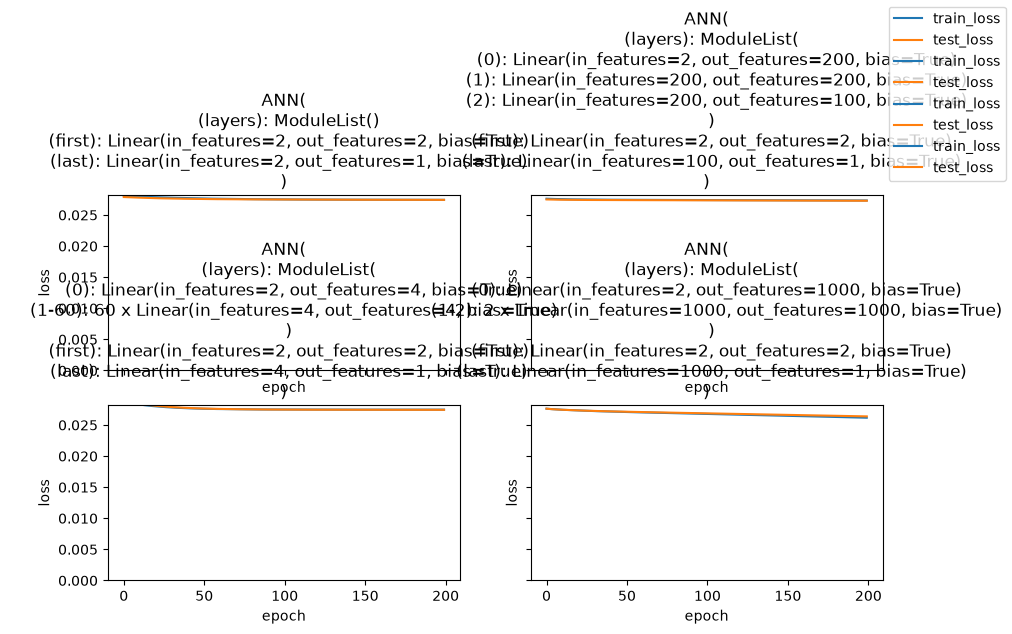

In [68]:
plot_results([train_result1, train_result2, train_result3, train_result4])